In [1]:
# Notebook cell 1
import math
import sys
from pathlib import Path
from typing import Dict, Tuple, List

import numpy as np

# Make project imports work even if notebook is placed in project root or nearby
PROJECT_ROOT_CANDIDATES = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
]

for cand in PROJECT_ROOT_CANDIDATES:
    if (cand / "env" / "env_manager.py").exists():
        if str(cand) not in sys.path:
            sys.path.insert(0, str(cand))
        break

from env.env_manager import GridSpec, FoVSpec, GridEnvManager

Cell = Tuple[int, int]  # (cx, cy)

# --- Grid / FoV: match controller ---
ARENA_WIDTH_M = 5.5
ARENA_HEIGHT_M = 6.5
CELL_SIZE_M = 0.5

GRID_COLS = int(ARENA_WIDTH_M / CELL_SIZE_M)   # 11
GRID_ROWS = int(ARENA_HEIGHT_M / CELL_SIZE_M)  # 13

MIN_X = -ARENA_WIDTH_M / 2.0
MAX_X = ARENA_WIDTH_M / 2.0
MIN_Y = -ARENA_HEIGHT_M / 2.0
MAX_Y = ARENA_HEIGHT_M / 2.0

# Use your corrected width
FOV_WIDTH_M = 1.40
FOV_FORWARD_M = 0.55
FOV_BACKWARD_M = 0.45

# --- Planner params: match current policy ---
P_FA = 0.05
PLANNING_P_HIT = 0.85
BETA_INFO = 1.0
PREFER_DETECT_STRENGTH = 0.95

# Same yaw set as policy
YAW_OPTIONS = [k * (math.pi / 4.0) for k in range(8)]

# Same coverage cutoff used inside _efe_components()
PLANNING_IG_COVERAGE_THRESHOLD = 0.05

C = np.array([1.0 - PREFER_DETECT_STRENGTH, PREFER_DETECT_STRENGTH], dtype=np.float64)

grid_spec = GridSpec(
    min_x=MIN_X,
    max_x=MAX_X,
    min_y=MIN_Y,
    max_y=MAX_Y,
    cell_size=CELL_SIZE_M,
    rows=GRID_ROWS,
    cols=GRID_COLS,
)

fov_spec = FoVSpec(
    half_left=FOV_WIDTH_M / 2.0,
    half_right=FOV_WIDTH_M / 2.0,
    forward=FOV_FORWARD_M,
    backward=FOV_BACKWARD_M,
)

env_mgr = GridEnvManager(grid_spec, fov_spec)

CURRENT_CELL = (0, 0)

print("Grid:", GRID_COLS, "x", GRID_ROWS)
print("Current cell:", CURRENT_CELL)

Grid: 11 x 13
Current cell: (0, 0)


In [2]:
# Notebook cell 2
def cell_center_xy(cell: Cell) -> Tuple[float, float]:
    cx, cy = cell
    x0 = grid_spec.min_x + cx * grid_spec.cell_size
    y0 = grid_spec.min_y + cy * grid_spec.cell_size
    cs = grid_spec.cell_size
    return (x0 + 0.5 * cs, y0 + 0.5 * cs)

def distance_between_cells(cell_a: Cell, cell_b: Cell) -> float:
    xa, ya = cell_center_xy(cell_a)
    xb, yb = cell_center_xy(cell_b)
    return math.hypot(xb - xa, yb - ya)

def make_q_s(prior_present_map: Dict[Cell, float]) -> np.ndarray:
    """
    Build q_s exactly like policy tensor:
      q_s[cy, cx, 0] = P(absent)
      q_s[cy, cx, 1] = P(present)
    Cells not mentioned default to present=0.0.
    """
    q_s = np.zeros((GRID_ROWS, GRID_COLS, 2), dtype=np.float64)
    q_s[:, :, 0] = 1.0
    q_s[:, :, 1] = 0.0

    for (cx, cy), p_present in prior_present_map.items():
        p_present = float(np.clip(p_present, 0.0, 1.0))
        q_s[cy, cx, 1] = p_present
        q_s[cy, cx, 0] = 1.0 - p_present

    return q_s

def efe_components(q_s: np.ndarray, target_cell: Cell, target_yaw: float) -> Tuple[float, float]:
    """
    Exact same logic as policy._efe_components()
    Returns (risk, IG).
    """
    tx, ty = cell_center_xy(target_cell)
    cov_rc = env_mgr.compute_cell_coverages(tx, ty, target_yaw)

    A = np.array(
        [
            [1.0 - P_FA, 1.0 - PLANNING_P_HIT],
            [P_FA,       PLANNING_P_HIT],
        ],
        dtype=np.float64,
    )

    IG = 0.0
    for (r, c), frac in cov_rc.items():
        frac = float(frac)
        if frac <= PLANNING_IG_COVERAGE_THRESHOLD:
            continue

        cy = int(r)
        cx = int(c)
        prior = q_s[cy, cx, :]

        p_o = A @ prior
        ig_cell = 0.0

        for o in (0, 1):
            po = float(p_o[o])
            if po <= 1e-12:
                continue
            post = A[o, :] * prior
            z = float(post.sum())
            if z <= 1e-12:
                continue
            post = post / z
            kl = float(np.sum(post * (np.log(post + 1e-12) - np.log(prior + 1e-12))))
            ig_cell += po * kl

        IG += frac * ig_cell

    cx_t, cy_t = target_cell
    prior_t = q_s[cy_t, cx_t, :]
    p_o_t = A @ prior_t
    risk = float(np.sum(p_o_t * (np.log(p_o_t + 1e-12) - np.log(C + 1e-12))))

    return float(risk), float(IG)

def action_core_score(q_s: np.ndarray, cell: Cell, yaw: float) -> float:
    """
    G without epsilon*distance term.
    """
    risk, IG = efe_components(q_s, cell, yaw)
    return float(risk - BETA_INFO * IG)

def best_action_for_epsilon(q_s: np.ndarray, epsilon: float, current_cell: Cell = CURRENT_CELL):
    """
    Exact same action search idea as planner:
      G = core + epsilon * distance
    over all cells and all yaws.
    """
    best = None
    best_G = float("inf")

    for cy in range(GRID_ROWS):
        for cx in range(GRID_COLS):
            cell = (cx, cy)
            dist = distance_between_cells(current_cell, cell)
            for yaw in YAW_OPTIONS:
                core = action_core_score(q_s, cell, yaw)
                G = core + epsilon * dist
                if G < best_G:
                    best_G = G
                    best = {
                        "cell": cell,
                        "yaw": yaw,
                        "core": core,
                        "distance": dist,
                        "G": G,
                    }

    return best

def stay_best_core(q_s: np.ndarray, current_cell: Cell = CURRENT_CELL):
    """
    Best stay score across yaw options.
    """
    best_core = float("inf")
    best_yaw = None

    for yaw in YAW_OPTIONS:
        core = action_core_score(q_s, current_cell, yaw)
        if core < best_core:
            best_core = core
            best_yaw = yaw

    return best_core, best_yaw

def epsilon_threshold_for_stay(q_s: np.ndarray, current_cell: Cell = CURRENT_CELL):
    """
    Analytic threshold:
    stay is optimal for all epsilon >= eps_star

    For each non-stay action:
      stay_core <= move_core + eps * dist
      eps >= (stay_core - move_core) / dist

    The critical epsilon is the maximum positive RHS over all non-stay actions/yaws.
    """
    stay_core, stay_yaw = stay_best_core(q_s, current_cell=current_cell)

    best_threshold = 0.0
    best_competitor = None

    for cy in range(GRID_ROWS):
        for cx in range(GRID_COLS):
            cell = (cx, cy)
            if cell == current_cell:
                continue

            dist = distance_between_cells(current_cell, cell)
            if dist <= 1e-12:
                continue

            for yaw in YAW_OPTIONS:
                move_core = action_core_score(q_s, cell, yaw)
                eps_needed = (stay_core - move_core) / dist

                if eps_needed > best_threshold:
                    best_threshold = eps_needed
                    best_competitor = {
                        "cell": cell,
                        "yaw": yaw,
                        "distance": dist,
                        "move_core": move_core,
                        "stay_core": stay_core,
                        "eps_threshold": eps_needed,
                    }

    return {
        "stay_core": stay_core,
        "stay_yaw": stay_yaw,
        "epsilon_star": max(0.0, best_threshold),
        "competitor": best_competitor,
    }

In [3]:
# Notebook cell 3 — corrected scenario builders
def local_corner_block(corner: Cell) -> tuple[list[Cell], Cell | None]:
    """
    Returns the 2 orthogonal neighbors + diagonal that form the local 2x2 block
    anchored at `corner`, but always extending inward into the grid.

    For example:
      (10,12) -> orth=[(9,12),(10,11)], diag=(9,11)
      (10,0)  -> orth=[(9,0),(10,1)],  diag=(9,1)
    """
    cx, cy = corner

    # Horizontal inward neighbor
    nx = cx - 1 if cx == GRID_COLS - 1 else cx + 1
    # Vertical inward neighbor
    ny = cy - 1 if cy == GRID_ROWS - 1 else cy + 1

    orth = []
    if 0 <= nx < GRID_COLS:
        orth.append((nx, cy))
    if 0 <= ny < GRID_ROWS:
        orth.append((cx, ny))

    diag = (nx, ny)
    if not (0 <= diag[0] < GRID_COLS and 0 <= diag[1] < GRID_ROWS):
        diag = None

    return orth, diag


def scenario_single_cell(corner: Cell, base_prior: float = 0.05) -> Dict[Cell, float]:
    """
    Only the corner cell has non-zero prior.
    """
    return {corner: base_prior}


def scenario_corner_plus_edges(corner: Cell, base_prior: float = 0.05) -> Dict[Cell, float]:
    """
    Corner and the two orthogonal edge-neighbor cells have base prior.
    Diagonal is zero.
    """
    priors = {corner: base_prior}
    orth, diag = local_corner_block(corner)
    for cell in orth:
        priors[cell] = base_prior
    return priors


def scenario_corner_base_neighbors_low(
    corner: Cell,
    corner_prior: float = 0.05,
    neighbor_prior: float = 0.02,
) -> Dict[Cell, float]:
    """
    All 4 cells in the local 2x2 corner block are non-zero:
      - corner cell at corner_prior
      - orthogonal neighbors + diagonal at neighbor_prior
    """
    priors = {corner: corner_prior}
    orth, diag = local_corner_block(corner)

    for cell in orth:
        priors[cell] = neighbor_prior
    if diag is not None:
        priors[diag] = neighbor_prior

    return priors


SCENARIOS = {
    "opposite_corner__single": scenario_single_cell((10, 12)),
    "opposite_corner__corner_plus_edges": scenario_corner_plus_edges((10, 12)),
    "opposite_corner__corner_base_neighbors_low": scenario_corner_base_neighbors_low((10, 12)),

    "short_wall_corner__single": scenario_single_cell((10, 0)),
    "short_wall_corner__corner_plus_edges": scenario_corner_plus_edges((10, 0)),
    "short_wall_corner__corner_base_neighbors_low": scenario_corner_base_neighbors_low((10, 0)),
}

for name, priors in SCENARIOS.items():
    print(name, "->", priors)

opposite_corner__single -> {(10, 12): 0.05}
opposite_corner__corner_plus_edges -> {(10, 12): 0.05, (9, 12): 0.05, (10, 11): 0.05}
opposite_corner__corner_base_neighbors_low -> {(10, 12): 0.05, (9, 12): 0.02, (10, 11): 0.02, (9, 11): 0.02}
short_wall_corner__single -> {(10, 0): 0.05}
short_wall_corner__corner_plus_edges -> {(10, 0): 0.05, (9, 0): 0.05, (10, 1): 0.05}
short_wall_corner__corner_base_neighbors_low -> {(10, 0): 0.05, (9, 0): 0.02, (10, 1): 0.02, (9, 1): 0.02}


In [4]:
# Notebook cell 4
def summarize_scenario(name: str, prior_map: Dict[Cell, float]):
    q_s = make_q_s(prior_map)
    out = epsilon_threshold_for_stay(q_s, current_cell=CURRENT_CELL)
    comp = out["competitor"]

    print(f"\n=== {name} ===")
    print("non-zero priors:", prior_map)
    print(f"best stay core      : {out['stay_core']:.6f} at yaw={out['stay_yaw']:.3f}")
    print(f"critical epsilon    : {out['epsilon_star']:.6f}")

    if comp is not None:
        print(f"binding competitor  : cell={comp['cell']} yaw={comp['yaw']:.3f}")
        print(f"competitor core     : {comp['move_core']:.6f}")
        print(f"distance            : {comp['distance']:.6f}")
        print(f"eps threshold       : {comp['eps_threshold']:.6f}")

results = {}
for name, prior_map in SCENARIOS.items():
    summarize_scenario(name, prior_map)
    results[name] = epsilon_threshold_for_stay(make_q_s(prior_map))


=== opposite_corner__single ===
non-zero priors: {(10, 12): 0.05}
best stay core      : 2.649995 at yaw=0.000
critical epsilon    : 0.040282
binding competitor  : cell=(10, 12) yaw=0.785
competitor core     : 2.335382
distance            : 7.810250
eps threshold       : 0.040282

=== opposite_corner__corner_plus_edges ===
non-zero priors: {(10, 12): 0.05, (9, 12): 0.05, (10, 11): 0.05}
best stay core      : 2.649995 at yaw=0.000
critical epsilon    : 0.061698
binding competitor  : cell=(10, 12) yaw=3.927
competitor core     : 2.168121
distance            : 7.810250
eps threshold       : 0.061698

=== opposite_corner__corner_base_neighbors_low ===
non-zero priors: {(10, 12): 0.05, (9, 12): 0.02, (10, 11): 0.02, (9, 11): 0.02}
best stay core      : 2.649995 at yaw=0.000
critical epsilon    : 0.051167
binding competitor  : cell=(10, 12) yaw=2.356
competitor core     : 2.250365
distance            : 7.810250
eps threshold       : 0.051167

=== short_wall_corner__single ===
non-zero priors

In [5]:
# Notebook cell 5
# Change this and re-run
EPSILON_TO_TEST = 0.02

for name, prior_map in SCENARIOS.items():
    q_s = make_q_s(prior_map)
    best = best_action_for_epsilon(q_s, epsilon=EPSILON_TO_TEST, current_cell=CURRENT_CELL)
    thr = epsilon_threshold_for_stay(q_s, current_cell=CURRENT_CELL)["epsilon_star"]

    print(f"\n=== {name} ===")
    print(f"epsilon tested      : {EPSILON_TO_TEST:.6f}")
    print(f"analytic threshold  : {thr:.6f}")
    print(f"best action         : cell={best['cell']} yaw={best['yaw']:.3f}")
    print(f"distance            : {best['distance']:.6f}")
    print(f"core                : {best['core']:.6f}")
    print(f"G                   : {best['G']:.6f}")
    print("stay?" if best["cell"] == CURRENT_CELL else "move?")


=== opposite_corner__single ===
epsilon tested      : 0.020000
analytic threshold  : 0.040282
best action         : cell=(10, 12) yaw=0.785
distance            : 7.810250
core                : 2.335382
G                   : 2.491587
move?

=== opposite_corner__corner_plus_edges ===
epsilon tested      : 0.020000
analytic threshold  : 0.061698
best action         : cell=(10, 12) yaw=3.927
distance            : 7.810250
core                : 2.168121
G                   : 2.324326
move?

=== opposite_corner__corner_base_neighbors_low ===
epsilon tested      : 0.020000
analytic threshold  : 0.051167
best action         : cell=(10, 12) yaw=2.356
distance            : 7.810250
core                : 2.250365
G                   : 2.406570
move?

=== short_wall_corner__single ===
epsilon tested      : 0.020000
analytic threshold  : 0.062923
best action         : cell=(10, 0) yaw=0.000
distance            : 5.000000
core                : 2.335382
G                   : 2.435382
move?

=== shor

In [6]:
# Notebook cell 6
# Pick one scenario name from SCENARIOS
SCENARIO_NAME = "opposite_corner__single"

prior_map = SCENARIOS[SCENARIO_NAME]
q_s = make_q_s(prior_map)
thr = epsilon_threshold_for_stay(q_s, current_cell=CURRENT_CELL)["epsilon_star"]

eps_values = np.linspace(max(0.0, thr - 0.05), thr + 0.05, 11)

print("scenario:", SCENARIO_NAME)
print("critical epsilon:", thr)

for eps in eps_values:
    best = best_action_for_epsilon(q_s, epsilon=float(eps), current_cell=CURRENT_CELL)
    print(
        f"eps={eps:.6f}  best_cell={best['cell']}  yaw={best['yaw']:.3f}  "
        f"dist={best['distance']:.3f}  G={best['G']:.6f}"
    )

scenario: opposite_corner__single
critical epsilon: 0.040282070292410134
eps=0.000000  best_cell=(10, 12)  yaw=0.785  dist=7.810  G=2.335382
eps=0.009028  best_cell=(10, 12)  yaw=0.785  dist=7.810  G=2.405895
eps=0.018056  best_cell=(10, 12)  yaw=0.785  dist=7.810  G=2.476407
eps=0.027085  best_cell=(10, 12)  yaw=0.785  dist=7.810  G=2.546920
eps=0.036113  best_cell=(10, 12)  yaw=0.785  dist=7.810  G=2.617432
eps=0.045141  best_cell=(0, 0)  yaw=0.000  dist=0.000  G=2.649995
eps=0.054169  best_cell=(0, 0)  yaw=0.000  dist=0.000  G=2.649995
eps=0.063197  best_cell=(0, 0)  yaw=0.000  dist=0.000  G=2.649995
eps=0.072226  best_cell=(0, 0)  yaw=0.000  dist=0.000  G=2.649995
eps=0.081254  best_cell=(0, 0)  yaw=0.000  dist=0.000  G=2.649995
eps=0.090282  best_cell=(0, 0)  yaw=0.000  dist=0.000  G=2.649995


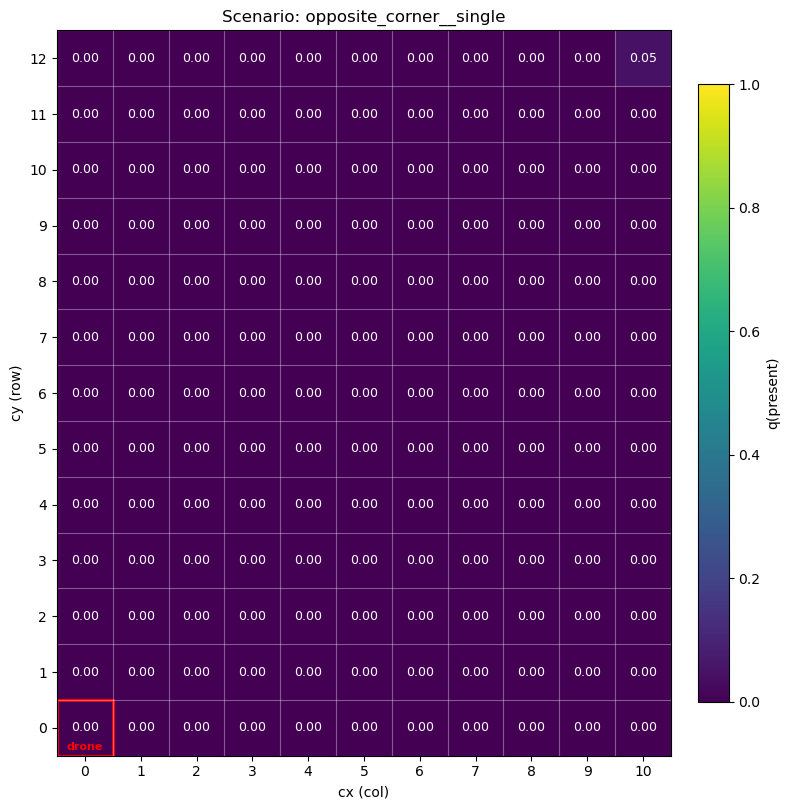

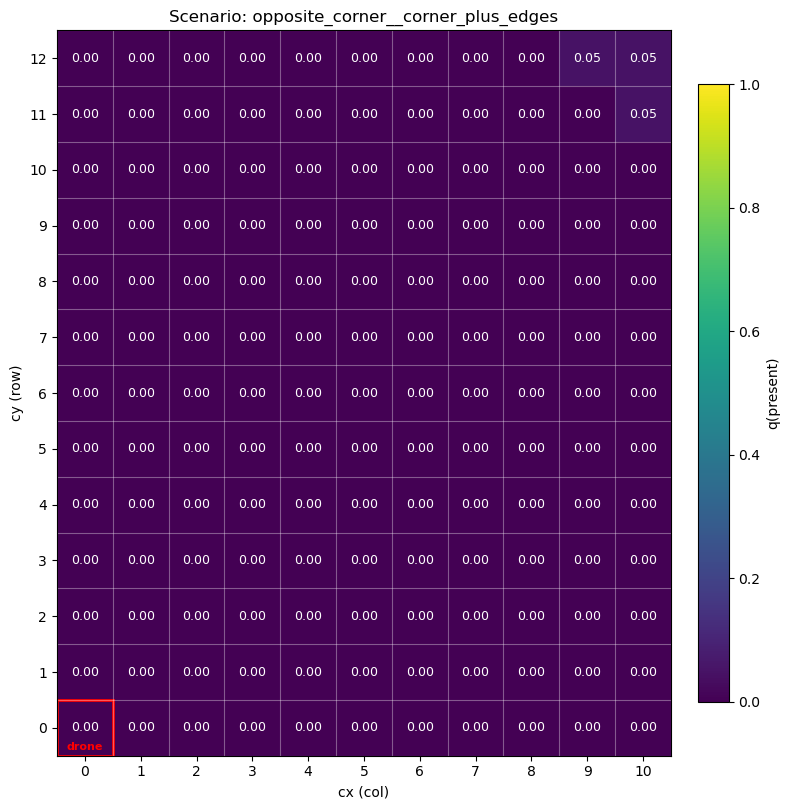

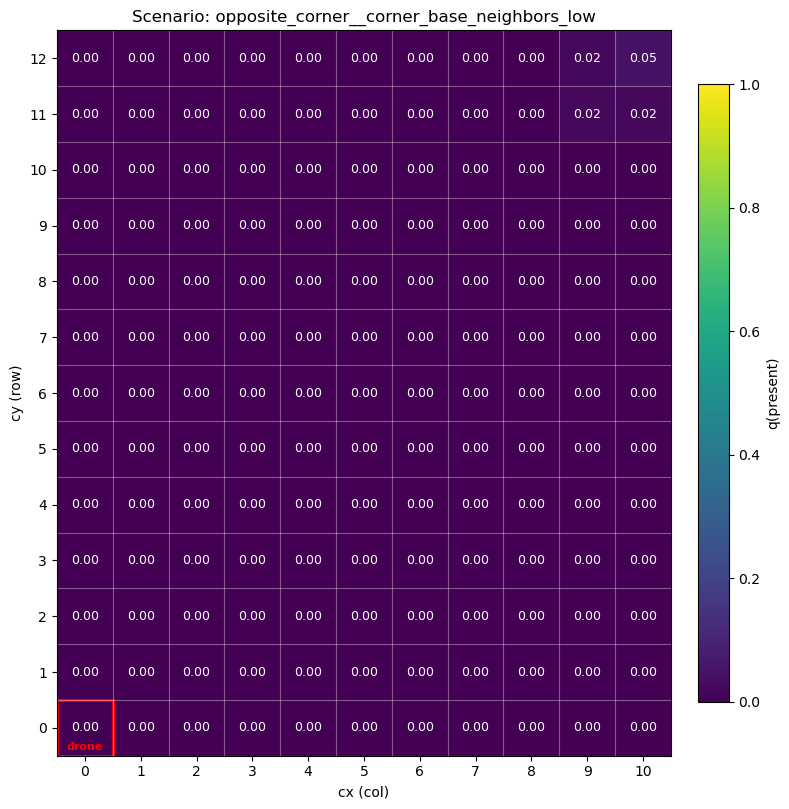

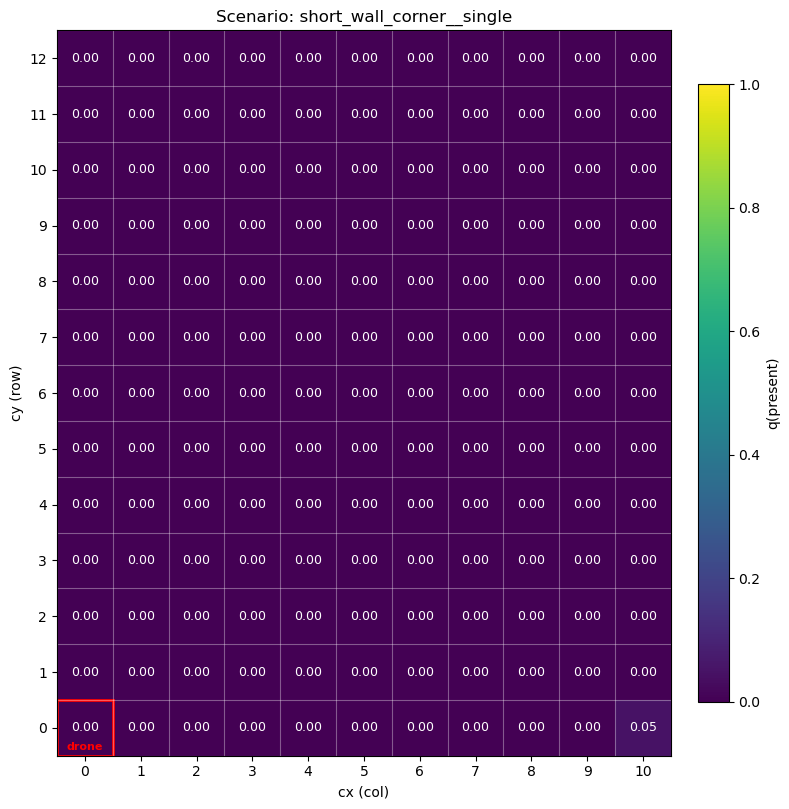

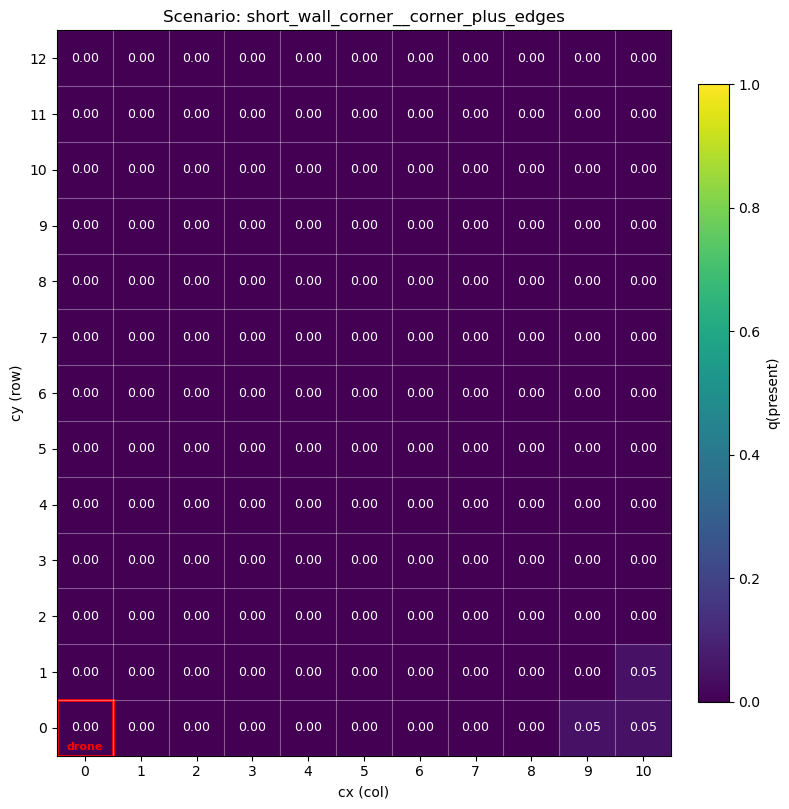

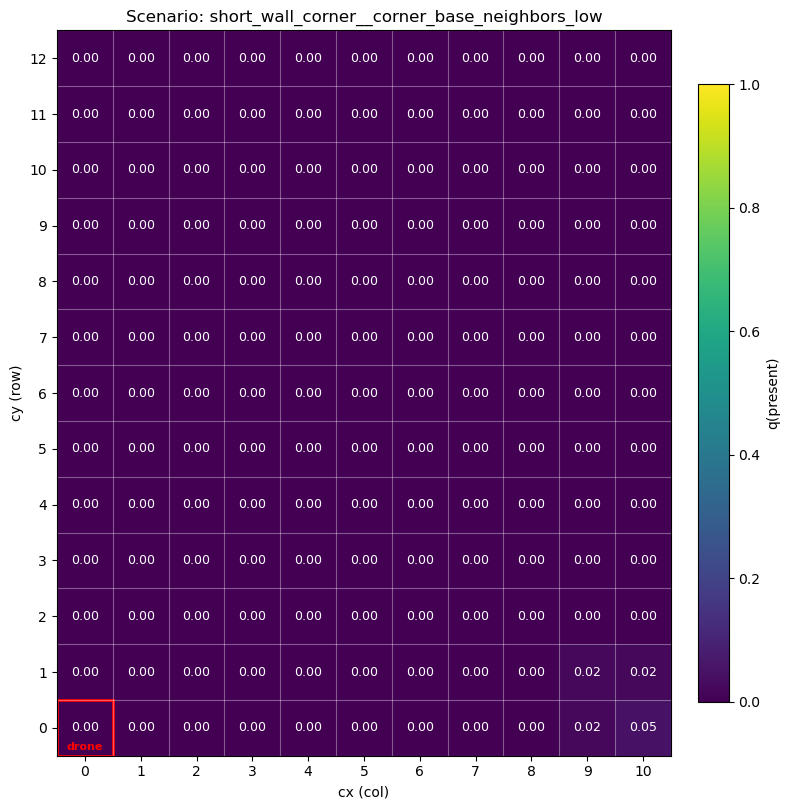

In [7]:
# Notebook cell 7
import matplotlib.pyplot as plt

def plot_belief_heatmap_from_prior_map(
    prior_map: Dict[Cell, float],
    *,
    title: str = "",
    annotate: bool = True,
    current_cell: Cell = CURRENT_CELL,
    vmin: float = 0.0,
    vmax: float = 1.0,
):
    q_s = make_q_s(prior_map)
    q_present = q_s[:, :, 1]

    fig, ax = plt.subplots(figsize=(8, 9))

    im = ax.imshow(
        q_present,
        origin="lower",
        vmin=vmin,
        vmax=vmax,
        cmap="viridis",
        aspect="equal",
    )

    ax.set_title(title or "Belief heatmap: q(present) per cell")
    ax.set_xlabel("cx (col)")
    ax.set_ylabel("cy (row)")

    ax.set_xticks(np.arange(GRID_COLS))
    ax.set_yticks(np.arange(GRID_ROWS))

    # Grid lines
    ax.set_xticks(np.arange(-0.5, GRID_COLS, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, GRID_ROWS, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=0.8, alpha=0.35)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Highlight current cell
    ccx, ccy = current_cell
    rect = plt.Rectangle(
        (ccx - 0.5, ccy - 0.5),
        1.0,
        1.0,
        fill=False,
        edgecolor="red",
        linewidth=2.0,
    )
    ax.add_patch(rect)
    ax.text(
        ccx,
        ccy - 0.35,
        "drone",
        color="red",
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
    )

    # Numeric annotations
    if annotate:
        for cy in range(GRID_ROWS):
            for cx in range(GRID_COLS):
                val = float(q_present[cy, cx])
                text_color = "white" if val < 0.6 else "black"
                ax.text(
                    cx,
                    cy,
                    f"{val:.2f}",
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=9,
                )

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("q(present)")

    plt.tight_layout()
    plt.show()

def plot_all_scenarios_heatmaps():
    for name, prior_map in SCENARIOS.items():
        plot_belief_heatmap_from_prior_map(
            prior_map,
            title=f"Scenario: {name}",
            annotate=True,
            current_cell=CURRENT_CELL,
        )

# Run all scenario heatmaps
plot_all_scenarios_heatmaps()

## Interpreting the epsilon threshold for “stay vs move”

The planner evaluates each candidate action by minimizing:

$$
G = \mathrm{risk} - \beta_{\mathrm{info}} \, IG + \epsilon \, d
$$

where:

- $\mathrm{risk}$ measures mismatch with preferred observations
- $IG$ is expected information gain
- $\beta_{\mathrm{info}}$ weights exploration
- $\epsilon$ is the distance-cost coefficient
- $d$ is the Euclidean distance from the current cell to the target cell

For a **stay** action, $d=0$, so:

$$
G_{\mathrm{stay}} = G_{\mathrm{stay,core}}
$$

For a **move** action:

$$
G_{\mathrm{move}} = G_{\mathrm{move,core}} + \epsilon d
$$

where:

$$
G_{\mathrm{move,core}} = \mathrm{risk} - \beta_{\mathrm{info}} \, IG
$$

The move is preferred over stay when:

$$
G_{\mathrm{move,core}} + \epsilon d < G_{\mathrm{stay,core}}
$$

Rearranging gives the critical epsilon value for that move:

$$
\epsilon^\star = \frac{G_{\mathrm{stay,core}} - G_{\mathrm{move,core}}}{d}
$$

### Meaning of the threshold

- If $\epsilon < \epsilon^\star$, the move beats stay.
- If $\epsilon > \epsilon^\star$, stay beats the move.

So:

- a **small** threshold means the move is **fragile** and is suppressed by distance cost easily
- a **large** threshold means the move is **robust** and remains preferable even for larger $\epsilon$

### Important consequence

When comparing several synthetic scenarios, the **most conservative safe epsilon** is the **minimum** threshold across them.

That minimum threshold answers:

> What is the largest epsilon such that even the most fragile tested scenario still chooses to move rather than stay?

So if the tested thresholds are, for example:

- scenario A: $\epsilon^\star = 0.0403$
- scenario B: $\epsilon^\star = 0.0996$

then choosing:

$$
\epsilon < 0.0403
$$

guarantees that the planner will choose a move instead of stay in **both** tested scenarios.

### Why the farthest move is not always the most fragile

The threshold depends on both:

- distance $d$
- the core score gap $G_{\mathrm{stay,core}} - G_{\mathrm{move,core}}$

A shorter move can still have a **larger** threshold if its core score is much better than staying.

Therefore, the “hardest” scenario for avoiding stuck behavior is not necessarily the one with the largest geometric distance; it is the one with the **smallest epsilon threshold**.